# Notebook 05: Baseline Forecasts and Chronological Validation
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Objective
Establish simple, reproducible benchmarks before fitting advanced models. A complex model must justify its added work by improving on a suitable baseline at the same horizon and on the same target rows.

## Forecast contract inherited from Notebook 04
- One batch issued at **23:50 on the previous day** forecasts all 144 ten-minute readings of the next calendar day.
- All targets in that day share one origin. Their leads range from **10 minutes to 24 hours**, with no within-day forecast updates.
- Forecasts use measurements available through the origin, assuming negligible reporting and fitting/processing delay.
- Training targets: January 9–August 31.
- Validation targets: September 1–October 31, **8,784 rows** across 61 complete days.
- November–December test errors are **not calculated in this notebook**. Final scoring is reserved for a later frozen comparison.
- Earlier notebooks explored the entire file descriptively; that exposure must be disclosed.

**Primary selection metric: validation MAE per zone.** RMSE, MAPE, WAPE, and signed bias provide supporting diagnostics. We declare the criterion before inspecting the comparison rather than selecting whichever metric favours a particular method.

We use source units, not unverified kW or energy units. Combined predictions are sums of simultaneous zone predictions.

## 1. Setup and Output Paths
Run Notebook 04 first. This notebook reads its feature table and manifest instead of rebuilding or silently redefining the predictors.

Every plot is saved as PNG and SVG. Validation predictions, scores, the historical calendar profile, and the chosen baseline rules are saved for later comparisons.

In [1]:
import sys
import importlib
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display

current_dir=Path.cwd().resolve()
PROJECT_ROOT=next((p for p in [current_dir,*current_dir.parents]
                   if (p/"src/config.py").is_file()),None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the Project folder containing src/config.py.")
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
import src.config as cfg
importlib.reload(cfg)
from src.config import PROCESSED_DIR,FIGURES_DIR,TABLES_DIR,MODELS_DIR,ZONES

BASE_FIGURES=FIGURES_DIR/"05_baseline_models"
BASE_TABLES=TABLES_DIR/"05_baseline_models"
BASE_MODELS=MODELS_DIR/"05_baselines_daily_batch"
for folder in [BASE_FIGURES,BASE_TABLES,BASE_MODELS]:folder.mkdir(parents=True,exist_ok=True)
SERIES=[*ZONES,"total"]
LABELS={"zone1":"Zone 1","zone2":"Zone 2","zone3":"Zone 3","total":"Combined"}
BASELINES=["origin_persistence","previous_day","previous_week","seven_day_mean","weekly_profile"]
BASE_LABELS={"origin_persistence":"Origin persistence","previous_day":"Previous day","previous_week":"Previous week",
             "seven_day_mean":"Seven-day mean","weekly_profile":"Weekly profile",
             "selected_per_zone":"Selected per zone"}
BASE_COLORS={"origin_persistence":"#777777","previous_day":"#0072B2","previous_week":"#D55E00","seven_day_mean":"#009E73",
             "weekly_profile":"#CC79A7","selected_per_zone":"#222222"}
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"font.size":11,"axes.spines.top":False,
                     "axes.spines.right":False,"svg.fonttype":"none"})

def save_table(table,name,index=True):
    table.to_csv(BASE_TABLES/f"{name}.csv",index=index,encoding="utf-8")

def show_figure(fig,name):
    fig.tight_layout()
    fig.savefig(BASE_FIGURES/f"{name}.png",dpi=200,bbox_inches="tight")
    fig.savefig(BASE_FIGURES/f"{name}.svg",bbox_inches="tight")
    plt.show()
    plt.close(fig)

def demand_axis(ax):ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

print("Python:",sys.executable)
print("Declared primary criterion: lowest validation MAE per zone.")

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
Declared primary criterion: lowest validation MAE per zone.


## 2. Validate the Saved Contract and Evaluation Window
Check file hashes so that stale features are detected if either the cleaned source or feature table changes after Notebook 04.

Split labels are read from the manifest's table. We verify the daily batch structure and confirm that the last fitted training label is available at or before every validation issue time.

In [2]:
manifest_path=PROCESSED_DIR/"tetuan_features_daily_batch_manifest.json"
manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
feature_path=PROCESSED_DIR/manifest["feature_file"]
clean_path=PROCESSED_DIR/manifest["source_file"]
assert manifest["design_id"]=="daily_batch_2350"
assert manifest["targets_per_issue"]==144 and manifest["step_minutes"]==10
assert manifest["lead_steps_min"]==1 and manifest["lead_steps_max"]==144
assert hashlib.sha256(clean_path.read_bytes()).hexdigest()==manifest["source_sha256"],"Rerun Notebook 04: cleaned source changed."
assert hashlib.sha256(feature_path.read_bytes()).hexdigest()==manifest["feature_sha256"],"Rerun Notebook 04: feature artifact changed."
panel=pd.read_parquet(feature_path)
assert len(panel)==manifest["retained_rows"]==51264
assert panel["target_time"].is_unique and panel["target_time"].is_monotonic_increasing
assert set(manifest["feature_columns"]).isdisjoint(manifest["target_columns"])
expected_origin=panel["target_time"].dt.normalize()-pd.Timedelta(minutes=10)
pd.testing.assert_series_equal(panel["origin_time"],expected_origin,check_names=False)
expected_lead=((panel["target_time"]-panel["origin_time"])/pd.Timedelta(minutes=10)).astype(int)
pd.testing.assert_series_equal(panel["lead_steps"],expected_lead,check_names=False)
assert panel["lead_steps"].between(1,144).all()
batch_groups=panel.groupby(panel["target_time"].dt.normalize())
assert batch_groups.size().eq(144).all()
assert batch_groups["origin_time"].nunique().eq(1).all()
assert batch_groups["lead_steps"].nunique().eq(144).all()
train=panel.loc[panel["split"].eq("train")].copy()
validation=panel.loc[panel["split"].eq("validation")].copy()
assert len(train)==33840 and len(validation)==8784
assert validation["target_time"].min()==pd.Timestamp("2017-09-01")
assert validation["target_time"].max()==pd.Timestamp("2017-10-31 23:50")
latest_fit_label=train["target_time"].max()
assert validation["origin_time"].ge(latest_fit_label).all()
assert validation.groupby(validation["target_time"].dt.normalize()).size().eq(144).all()
actual=validation.set_index("target_time")[[f"y_{z}" for z in ZONES]].rename(columns={f"y_{z}":z for z in ZONES})
actual["total"]=actual[ZONES].sum(axis=1)
assert actual.gt(0).all().all()
assert np.isfinite(actual.to_numpy()).all()
coverage=panel.groupby("split").agg(rows=("target_time","size"),first_target=("target_time","min"),last_target=("target_time","max"))
display(coverage)
save_table(coverage,"01_evaluation_coverage")
print("Validation origins:",validation["origin_time"].min(),"to",validation["origin_time"].max())
print("Latest fitted training label:",latest_fit_label)
print("Only validation target errors will be calculated.")

Validation origins: 2017-08-31 23:50:00 to 2017-10-30 23:50:00
Latest fitted training label: 2017-08-31 23:50:00
Only validation target errors will be calculated.


,rows,first_target,last_target
split,,,
test,8640,2017-11-01,2017-12-30 23:50:00
train,33840,2017-01-09,2017-08-31 23:50:00
validation,8784,2017-09-01,2017-10-31 23:50:00


### Interpretation: Fair Daily-Batch Evaluation
The comparison uses **61 complete target days**, September 1–October 31. The complete forecast for each day is issued at 23:50 the previous day; no observations arriving during the target day can update that batch.

After a validation day finishes, its measurements may become legitimate history for the next daily batch. That is permitted because they are already observed by the later issue time. We are not issuing all September–October batches from one fixed date.

The first validation issue is August 31 at 23:50, equal to the latest fitted training label timestamp. Equality is allowed under our explicit negligible-delay assumption. Thus September 1 can be scored without the one-day boundary gap used in the earlier fixed-24-hour rolling design. If operational reporting or model-fitting delays are material, the cutoff must be moved back before deployment.

The previous-day, previous-week, and seven-day-mean predictions are numerically unchanged on overlapping targets: all of those historical observations were already available at the daily issue time. Their new validation scores change primarily because **September 1 is now included**. The old and new scores must not be compared as if their target cohorts were identical. Origin persistence changes to a distinct flat daily-batch forecast.

## 3. Construct Five Baselines
1. **Origin persistence:** repeat the last available reading, recorded at 23:50, for all 144 targets. This is a flat next-day forecast.
2. **Previous day:** use the reading at t − 1 day for each target clock time. The complete previous-day profile is already known at issue time.
3. **Previous week:** use the reading at t − 7 days for each target clock time.
4. **Seven-day mean:** average the seven preceding daily readings at the target's exact clock time. This smooths daily noise but may react slowly to changing levels.
5. **Weekly profile:** fit a mean demand for each weekday and ten-minute clock slot using training targets only. Apply that fixed lookup during validation.

Origin persistence and the previous-day profile are now **different** baselines. Both use only information available at the common issue time, but only the previous-day rule preserves a daily shape.

The weekly profile uses 7 × 144 = 1,008 calendar groups, all represented in training. We avoid a month-based lookup because September and October are absent from the January–August training window.

None of these baselines uses observed target-time weather. The first four need no fitted parameters; the profile is fitted only on training labels.

In [3]:
predictions={}
feature_rules={"origin_persistence":"at_origin","previous_day":"target_lag_1d","previous_week":"target_lag_7d",
               "seven_day_mean":"previous7_same_clock_mean"}
for baseline,suffix in feature_rules.items():
    frame=pd.DataFrame(index=actual.index)
    for zone in ZONES:frame[zone]=validation[f"{zone}_{suffix}"].to_numpy()
    frame["total"]=frame[ZONES].sum(axis=1)
    predictions[baseline]=frame

profile_keys=["target_weekday","target_slot"]
profile=train.groupby(profile_keys)[[f"y_{z}" for z in ZONES]].mean()
assert len(profile)==1008 and profile.index.is_unique
lookup_keys=pd.MultiIndex.from_frame(validation[profile_keys])
looked_up=profile.reindex(lookup_keys)
assert looked_up.notna().all().all(),"An unseen calendar group requires investigation."
profile_prediction=pd.DataFrame(looked_up.to_numpy(),index=actual.index,columns=ZONES)
profile_prediction["total"]=profile_prediction[ZONES].sum(axis=1)
predictions["weekly_profile"]=profile_prediction
profile.to_csv(BASE_MODELS/"training_weekly_profile.csv",encoding="utf-8")

for baseline,frame in predictions.items():
    pd.testing.assert_index_equal(frame.index,actual.index)
    assert frame.shape==actual.shape and frame.notna().all().all()
    assert np.isfinite(frame.to_numpy()).all()
    assert np.allclose(frame[ZONES].sum(axis=1),frame["total"])
definition_table=pd.DataFrame({"baseline":BASELINES,
    "rule":["Repeat the one origin reading for the entire target day","Observed demand at target minus 1 day","Observed demand at target minus 7 days",
            "Mean previous seven daily same-clock observations","Training-only weekday × ten-minute-slot mean"],
    "fitting":["None","None","None","None",f"Training labels through {latest_fit_label}"]})
display(definition_table)
save_table(definition_table,"02_baseline_definitions",index=False)

,baseline,rule,fitting
0,origin_persistence,Repeat the one origin reading for the entire t...,None
1,previous_day,Observed demand at target minus 1 day,None
2,previous_week,Observed demand at target minus 7 days,None
3,seven_day_mean,Mean previous seven daily same-clock observations,None
4,weekly_profile,Training-only weekday × ten-minute-slot mean,Training labels through 2017-08-31 23:50:00


## 4. Independently Check Predictions Against Original Timestamps
Reconstruct all four measurement-based baselines directly from the checked dataset, using timestamp lookups rather than the saved shifted feature columns.

Agreement across every validation timestamp is an additional check that origin-relative and target-relative lags have not been confused.

In [4]:
history=pd.read_parquet(clean_path).set_index("datetime")
target_times=actual.index
issue_times=pd.DatetimeIndex(validation["origin_time"])
assert (target_times-pd.Timedelta(days=1)<=issue_times).all()
assert (target_times-pd.Timedelta(days=7)<=issue_times).all()
verification=[]
for zone in ZONES:
    persistence=history[zone].reindex(validation["origin_time"]).to_numpy()
    day=history[zone].reindex(target_times-pd.Timedelta(days=1)).to_numpy()
    week=history[zone].reindex(target_times-pd.Timedelta(days=7)).to_numpy()
    seven=np.column_stack([history[zone].reindex(target_times-pd.Timedelta(days=k)).to_numpy()
                           for k in range(1,8)]).mean(axis=1)
    for name,expected in [("origin_persistence",persistence),("previous_day",day),("previous_week",week),("seven_day_mean",seven)]:
        assert np.isfinite(expected).all()
        difference=np.max(np.abs(predictions[name][zone].to_numpy()-expected))
        assert np.allclose(predictions[name][zone],expected)
        verification.append({"zone":zone,"baseline":name,"maximum_absolute_difference":difference})
verification=pd.DataFrame(verification)
for zone in ZONES:
    assert predictions["origin_persistence"][zone].groupby(actual.index.normalize()).nunique().eq(1).all()
display(verification)
save_table(verification,"03_timestamp_prediction_checks",index=False)

,zone,baseline,maximum_absolute_difference
0,zone1,origin_persistence,0.0
1,zone1,previous_day,0.0
2,zone1,previous_week,0.0
3,zone1,seven_day_mean,0.0
4,zone2,origin_persistence,0.0
5,zone2,previous_day,0.0
6,zone2,previous_week,0.0
7,zone2,seven_day_mean,0.0
8,zone3,origin_persistence,0.0
9,zone3,previous_day,0.0


### Interpretation: Source-Time Checks Passed
The feature-based predictions match direct timestamp reconstructions for all four measurement-based baselines and all three zones. Origin-persistence predictions remain constant across each 144-target batch.

The weekly profile has a different verification: it uses training labels only, covers every validation calendar key, and its latest fitting label is available at or before all validation issue times. These checks establish valid information timing; they do not establish accuracy.

## 5. Define and Check Forecast Metrics
Let **error = prediction − actual**.
- **MAE:** mean absolute error, in demand source units. Lower is better.
- **RMSE:** square root of mean squared error, also in source units. It penalises large misses more strongly.
- **MAPE:** mean of absolute error divided by actual demand, multiplied by 100. Low-demand readings receive more relative weight.
- **WAPE:** sum of absolute errors divided by the sum of actual demand, multiplied by 100. This is an error ratio, not an energy calculation.
- **Bias:** mean signed error. Positive means average overprediction; negative means average underprediction.

Actual demand is positive throughout the scored window, so these percentage denominators are valid. We still check that condition explicitly.

In [5]:
def forecast_metrics(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=float)
    y_pred=np.asarray(y_pred,dtype=float)
    assert y_true.ndim==y_pred.ndim==1
    assert y_true.shape==y_pred.shape and y_true.size>0
    assert np.isfinite(y_true).all() and np.isfinite(y_pred).all()
    assert (y_true>0).all()
    error=y_pred-y_true
    return {"n":len(y_true),"MAE":np.abs(error).mean(),"RMSE":np.sqrt(np.mean(error**2)),
            "MAPE_pct":np.mean(np.abs(error)/y_true)*100,
            "WAPE_pct":np.abs(error).sum()/y_true.sum()*100,"bias":error.mean()}

# Hand-checkable example: errors are +10 and -20.
toy=forecast_metrics([100,200],[110,180])
assert np.isclose(toy["MAE"],15) and np.isclose(toy["RMSE"],np.sqrt(250))
assert np.isclose(toy["MAPE_pct"],10) and np.isclose(toy["WAPE_pct"],10)
assert np.isclose(toy["bias"],-5)
metric_rows=[]
for baseline in BASELINES:
    for series in SERIES:
        metric_rows.append({"baseline":baseline,"series":series,
            **forecast_metrics(actual[series],predictions[baseline][series])})
scores=pd.DataFrame(metric_rows)
assert scores["n"].eq(8784).all()
save_table(scores,"04_validation_baseline_scores",index=False)
for zone in SERIES:
    print(LABELS[zone])
    display(scores.loc[scores["series"].eq(zone)].set_index("baseline").round(3))

Zone 1
Zone 2
Zone 3
Combined


,series,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
baseline,,,,,,,
origin_persistence,zone1,8784,5598.150,6842.378,16.692,16.909,-1522.174
previous_day,zone1,8784,1304.418,1829.098,4.083,3.940,41.941
previous_week,zone1,8784,1806.997,2582.680,5.635,5.458,552.592
seven_day_mean,zone1,8784,1354.264,1899.141,4.259,4.091,292.328
weekly_profile,zone1,8784,1979.897,2643.831,6.139,5.980,-52.247


,series,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
baseline,,,,,,,
origin_persistence,zone2,8784,3806.685,4641.769,18.012,18.270,-1403.309
previous_day,zone2,8784,1371.172,1953.765,6.890,6.581,-84.848
previous_week,zone2,8784,1630.032,2342.753,7.941,7.823,-233.180
seven_day_mean,zone2,8784,1434.370,1972.272,7.231,6.884,-167.085
weekly_profile,zone2,8784,1627.410,2219.435,7.860,7.811,-323.302


,series,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
baseline,,,,,,,
origin_persistence,zone3,8784,2852.341,3401.319,21.442,20.258,935.599
previous_day,zone3,8784,713.345,1049.906,5.258,5.066,70.378
previous_week,zone3,8784,1230.012,1884.495,8.734,8.736,826.862
seven_day_mean,zone3,8784,711.299,1107.397,5.270,5.052,409.291
weekly_profile,zone3,8784,6238.185,6699.359,45.471,44.306,6238.185


,series,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
baseline,,,,,,,
origin_persistence,total,8784,11270.844,13959.155,16.560,16.569,-1989.885
previous_day,total,8784,2354.049,3403.155,3.640,3.461,27.471
previous_week,total,8784,3124.649,5313.420,4.710,4.594,1146.273
seven_day_mean,total,8784,2510.416,3827.220,3.869,3.691,534.534
weekly_profile,total,8784,6676.554,8008.097,9.833,9.815,5862.636


### Interpretation: The Baselines Set a Meaningful Benchmark
For Zone 1, previous-day MAE is approximately **1,304.42**; for Zone 2 it is **1,371.17**. The seven-day mean gives the lowest Zone 3 MAE, approximately **711.30 source units**.

Zone 3's seven-day mean only narrowly improves MAE over the previous-day rule (**711.30 versus 713.35**, about **0.29%**). The previous-day rule has better RMSE and MAPE for that zone. The small MAE advantage should not be described as decisive superiority across metrics.

The flat origin-persistence baseline has combined MAE approximately **11,270.84**, illustrating how repeating one late-evening value misses the next day's shape. The training-only weekly profile performs particularly poorly for Zone 3: MAE is approximately **6,238.19**, with positive bias of the same magnitude. It overpredicts every Zone 3 validation reading. A historical average can fail when the level changes between training and validation.

## 6. Compare Validation MAE Visually
Each panel compares the five baselines for one zone or the coherent combined prediction. Panels have separate y-scales because demand magnitudes differ.

The combined error is calculated after summing simultaneous predictions. It is not the sum of zone MAEs; positive and negative zone errors can offset one another.

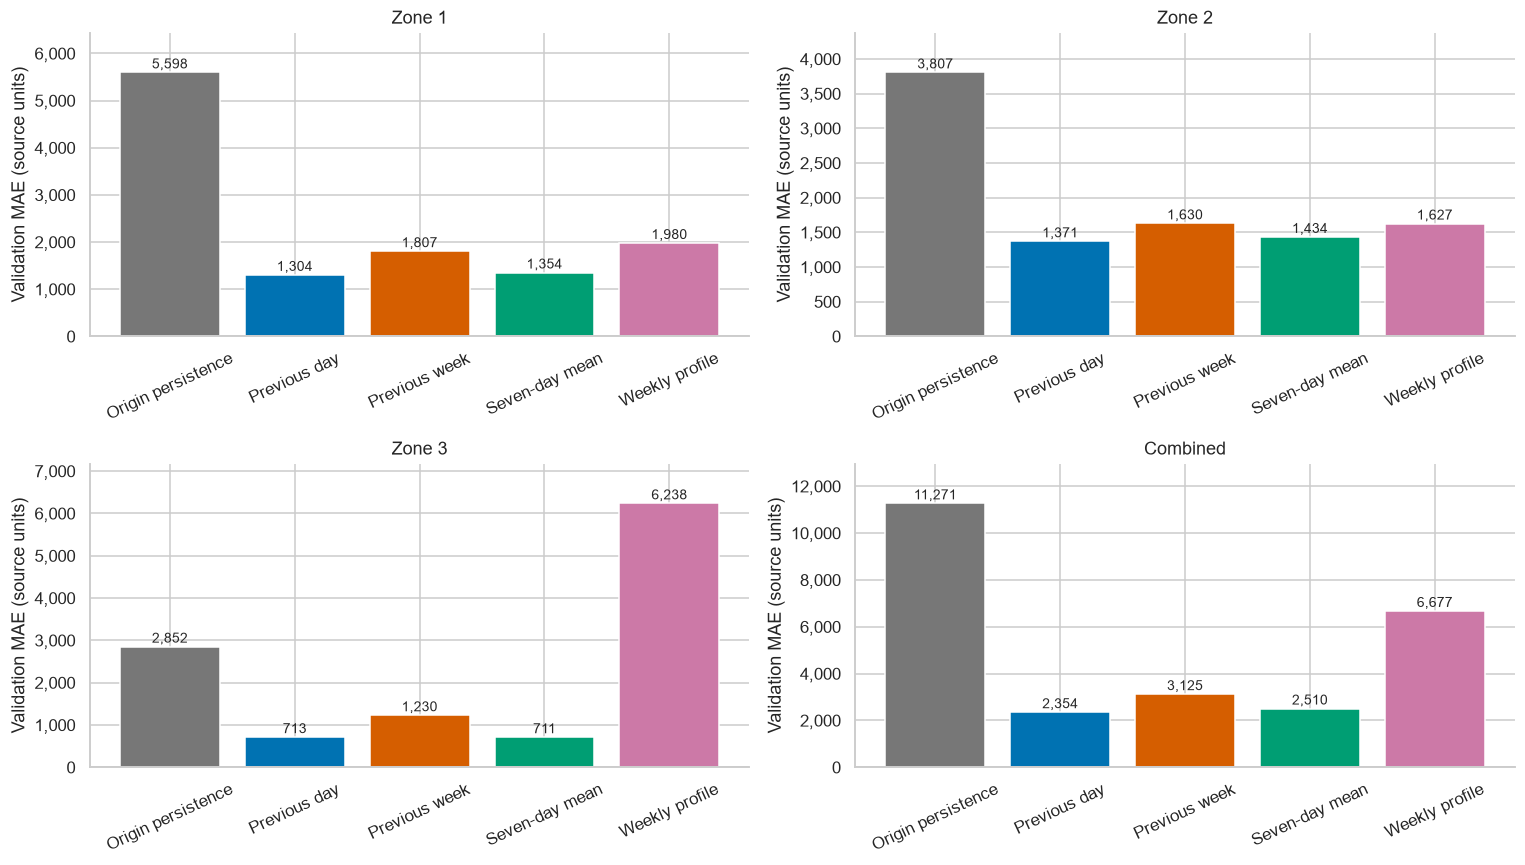

In [6]:
fig,axes=plt.subplots(2,2,figsize=(14,8))
for ax,series in zip(axes.flat,SERIES):
    values=scores.loc[scores["series"].eq(series)].set_index("baseline").loc[BASELINES,"MAE"]
    ax.bar([BASE_LABELS[b] for b in BASELINES],values,color=[BASE_COLORS[b] for b in BASELINES])
    for i,v in enumerate(values):ax.text(i,v+values.max()*.015,f"{v:,.0f}",ha="center",fontsize=9)
    ax.set(title=LABELS[series],ylabel="Validation MAE (source units)",ylim=(0,values.max()*1.15))
    ax.tick_params(axis="x",rotation=25)
    demand_axis(ax)
show_figure(fig,"01_validation_mae_comparison")

## 7. Select a Per-Zone Benchmark Using Validation MAE
Select the lowest-MAE baseline separately for each zone. An exact tie follows the fixed baseline order declared at setup. Supporting metrics remain visible.

The combined selected prediction is the sum of the three selected zone predictions. This is coherent across zones, but choosing each zone's MAE winner does not mathematically guarantee the lowest possible combined MAE across every mixture of rules.

These choices use validation outcomes. Their validation scores are therefore selection results, not independent final performance estimates.

In [7]:
champions={}
for zone in ZONES:
    ranked=scores.loc[scores["series"].eq(zone)].set_index("baseline").loc[BASELINES,"MAE"]
    champions[zone]=ranked.idxmin()
selected=pd.DataFrame({z:predictions[champions[z]][z] for z in ZONES},index=actual.index)
selected["total"]=selected[ZONES].sum(axis=1)
selected_scores=pd.DataFrame([{"series":s,"baseline":"selected_per_zone",
                              **forecast_metrics(actual[s],selected[s])} for s in SERIES])
choice_table=pd.DataFrame([{"zone":z,"selected_baseline":champions[z],
                           "validation_MAE":forecast_metrics(actual[z],selected[z])["MAE"]} for z in ZONES])
display(choice_table.round(3))
display(selected_scores.round(3))
save_table(choice_table,"05_selected_baseline_by_zone",index=False)
save_table(selected_scores,"06_selected_strategy_validation_scores",index=False)
assert np.allclose(selected[ZONES].sum(axis=1),selected["total"])
baseline_reference=scores.loc[scores["baseline"].eq("previous_day")].set_index("series")["MAE"]
improvement=scores.copy()
improvement["MAE_improvement_vs_previous_day_pct"]=[
    (1-row.MAE/baseline_reference[row.series])*100 for row in improvement.itertuples()]
save_table(improvement,"07_mae_improvement_vs_previous_day",index=False)

,zone,selected_baseline,validation_MAE
0,zone1,previous_day,1304.418
1,zone2,previous_day,1371.172
2,zone3,seven_day_mean,711.299


,series,baseline,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
0,zone1,selected_per_zone,8784,1304.418,1829.098,4.083,3.940,41.941
1,zone2,selected_per_zone,8784,1371.172,1953.765,6.890,6.581,-84.848
2,zone3,selected_per_zone,8784,711.299,1107.397,5.270,5.052,409.291
3,total,selected_per_zone,8784,2333.079,3489.827,3.612,3.430,366.383


### Interpretation: Benchmark Choices
- **Zone 1:** previous day, validation MAE **1,304.42**.
- **Zone 2:** previous day, validation MAE **1,371.17**.
- **Zone 3:** seven-day mean, validation MAE **711.30**.

Summing these zone predictions gives combined validation **MAE 2,333.08**, **RMSE 3,489.83**, and **MAPE 3.61%**. The uniform previous-day strategy has slightly higher combined MAE (**2,354.05**) but lower combined RMSE (**3,403.16**). The per-zone selection therefore does not win every combined metric. These are benchmarks selected on validation data, not final test claims.

Later advanced models should be compared against the corresponding zone benchmark on the same horizon and target rows, with MAE remaining the primary declared criterion.

## 8. Inspect a Fixed Validation Week
Plot actual demand and all five baseline forecasts for the first seven complete validation target days: September 1–7.

This fixed display window avoids choosing only the best-looking or worst-looking days. Each day's complete 144-point forecast was issued at 23:50 the previous day. It is not a seven-day-ahead forecast issued once or a forecast updated during each target day.

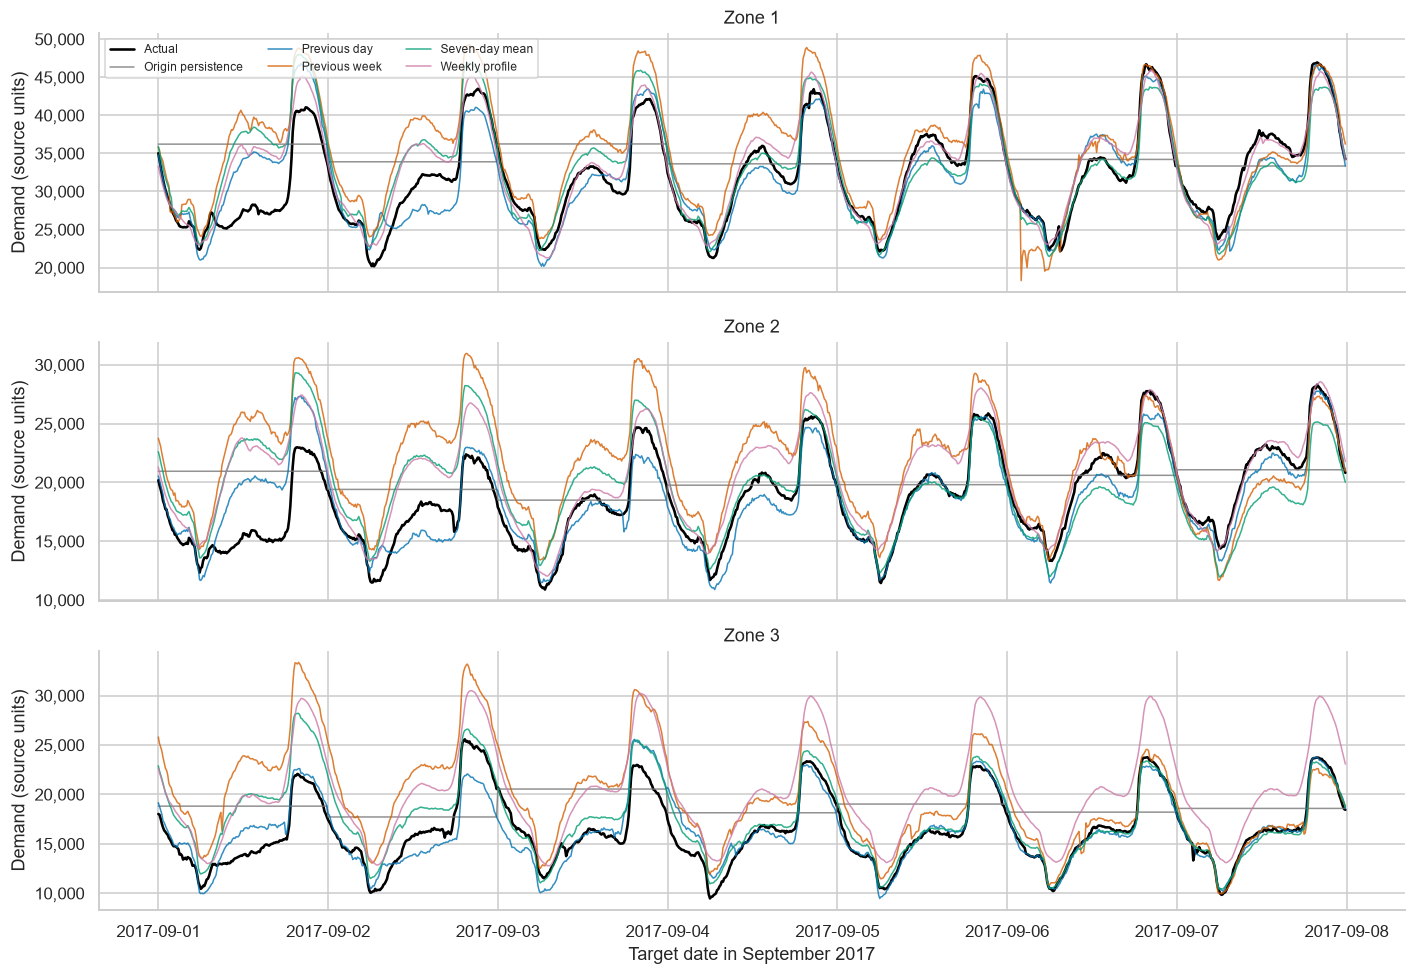

In [8]:
example_start=actual.index.min()
example_end=example_start+pd.Timedelta(days=7)
example_mask=(actual.index>=example_start)&(actual.index<example_end)
fig,axes=plt.subplots(3,1,figsize=(13,9),sharex=True)
for ax,zone in zip(axes,ZONES):
    ax.plot(actual.index[example_mask],actual.loc[example_mask,zone],color="black",linewidth=1.7,label="Actual")
    for baseline in BASELINES:
        ax.plot(actual.index[example_mask],predictions[baseline].loc[example_mask,zone],
                color=BASE_COLORS[baseline],alpha=.8,linewidth=1,label=BASE_LABELS[baseline])
    ax.set(title=LABELS[zone],ylabel="Demand (source units)")
    demand_axis(ax)
axes[0].legend(loc="upper left",ncol=3,fontsize=8)
axes[-1].set_xlabel("Target date in September 2017")
show_figure(fig,"02_first_validation_week_forecasts")

### Interpretation: Timing, Level, and Smoothing
The plots show whether a baseline misses the daily timing, the demand level, or unusual movements. A smooth historical profile can reproduce a typical daily shape while badly missing the current level.

The seven-day mean smooths across recent days, which can reduce isolated errors but also delay adjustment to a changing level. The previous-day and previous-week rules preserve an earlier day's shape, including that day's irregularities.

The full validation metric tables, rather than this one display week, determine the comparison.

## 9. Selected Prediction Scatterplots and Signed Errors
The identity line in each scatterplot represents a perfect prediction. Colour shows the number of paired observations per hexagon on a logarithmic count scale, with each panel's own count scale.

Signed-error histograms use prediction minus actual. The plotted bias line reports the mean signed error: a positive value means average overprediction. Histogram width describes the spread; its shape alone does not identify the mean. These are historical validation errors, not calibrated prediction intervals.

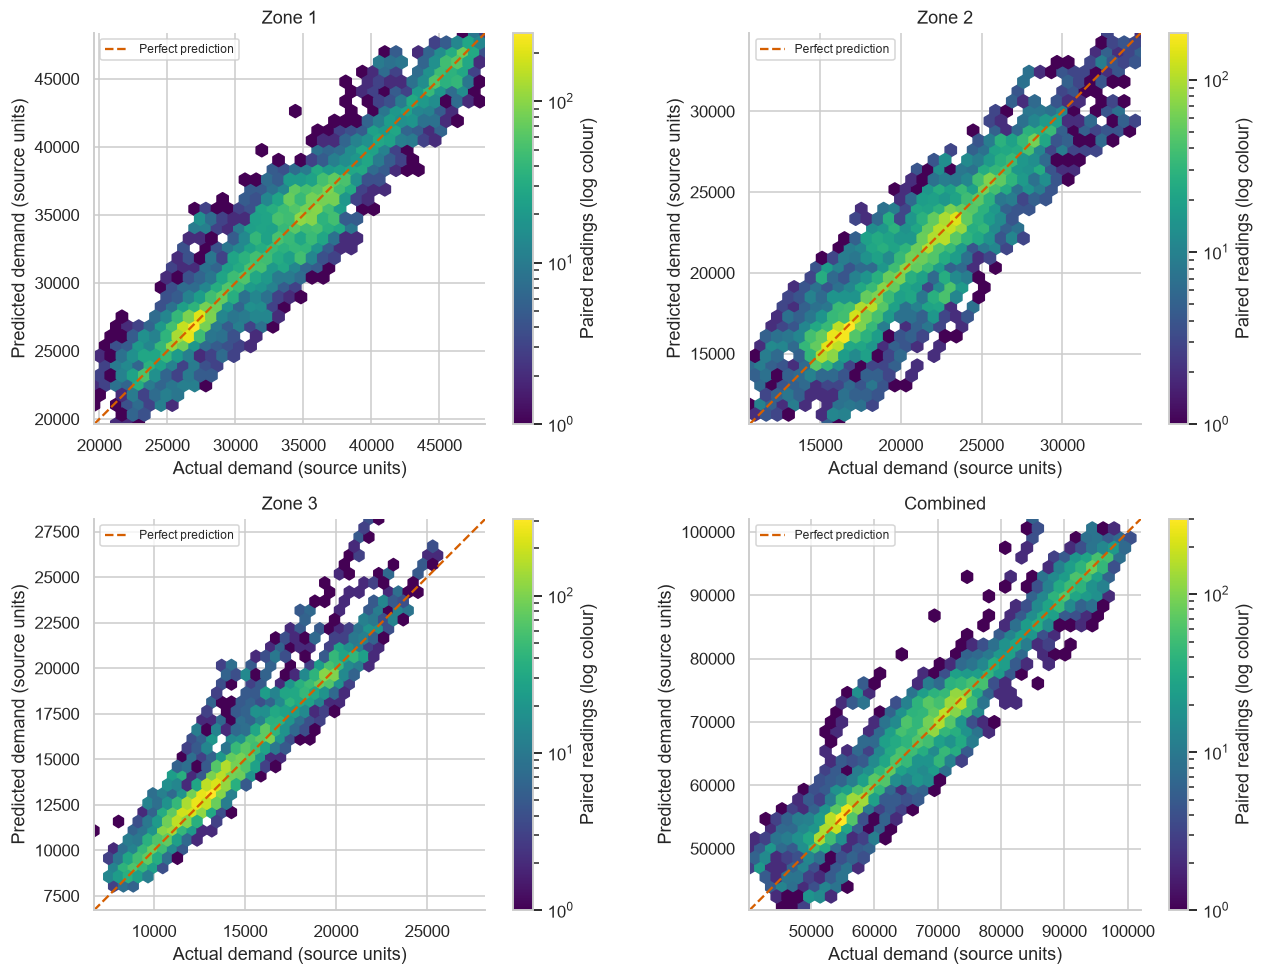

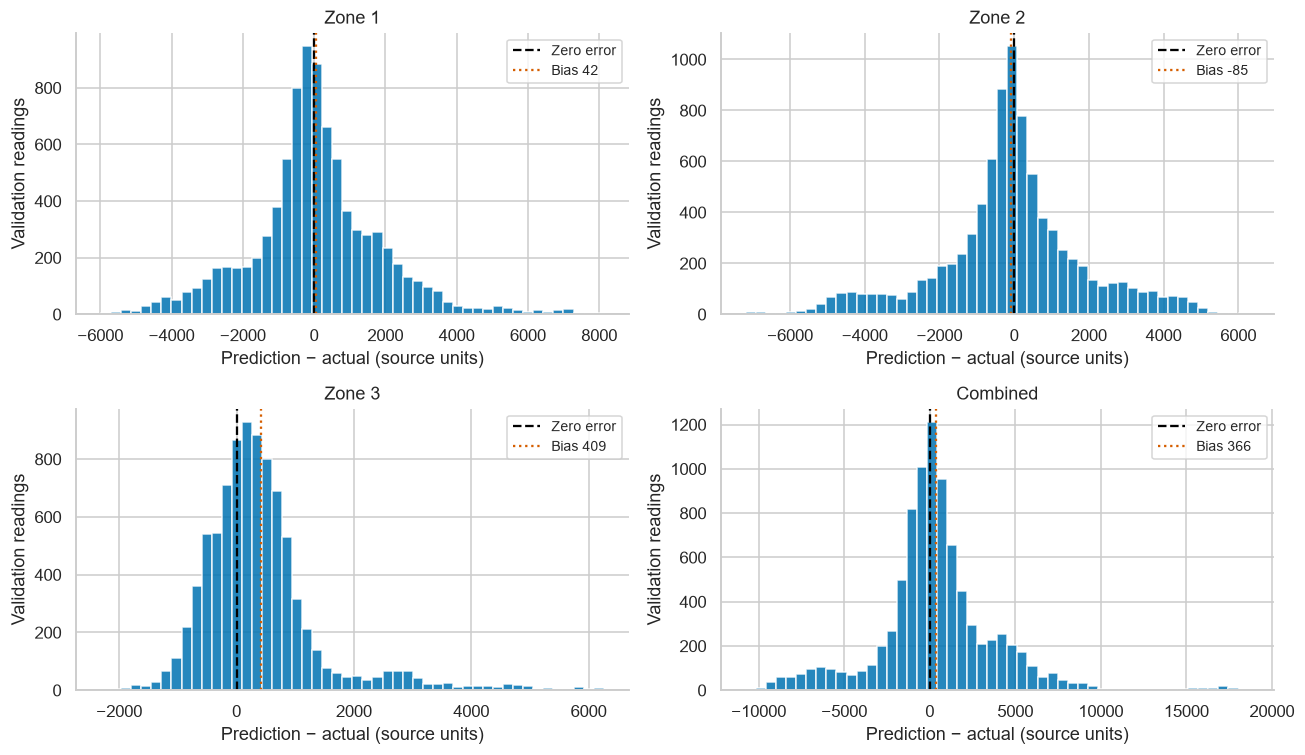

In [9]:
fig,axes=plt.subplots(2,2,figsize=(12,9))
for ax,series in zip(axes.flat,SERIES):
    hx=ax.hexbin(actual[series],selected[series],gridsize=35,bins="log",mincnt=1,cmap="viridis")
    low=min(actual[series].min(),selected[series].min())
    high=max(actual[series].max(),selected[series].max())
    ax.plot([low,high],[low,high],color="#D55E00",linestyle="--",label="Perfect prediction")
    ax.set(title=LABELS[series],xlabel="Actual demand (source units)",ylabel="Predicted demand (source units)",
           xlim=(low,high),ylim=(low,high))
    ax.set_aspect("equal",adjustable="box")
    ax.legend(fontsize=8)
    fig.colorbar(hx,ax=ax,label="Paired readings (log colour)")
show_figure(fig,"03_selected_actual_prediction_density")

selected_error=selected-actual
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,series in zip(axes.flat,SERIES):
    error=selected_error[series]
    ax.hist(error,bins=50,color="#0072B2",edgecolor="white",alpha=.85)
    ax.axvline(0,color="black",linestyle="--",label="Zero error")
    ax.axvline(error.mean(),color="#D55E00",linestyle=":",label=f"Bias {error.mean():,.0f}")
    ax.set(title=LABELS[series],xlabel="Prediction − actual (source units)",ylabel="Validation readings")
    ax.legend(fontsize=9)
show_figure(fig,"04_selected_signed_error_distributions")

### Interpretation: Overall Scores Hide Error Structure
Selected Zone 1 has average bias approximately **+41.94**, while Zone 2 has average bias approximately **−84.85**. Selected Zone 3 has positive bias, approximately **+409.29 source units**.

Their combined bias is approximately **+366.38**. Zone errors can offset in the combined series, so a good combined percentage error does not establish equally good accuracy for each zone.

The scatter and histogram views reveal spread and asymmetry that one MAE or MAPE value cannot show. We have not assumed independent or normally distributed errors.

## 10. Daily Errors and Difficult Days
Calculate daily mean absolute error for every baseline and series, plus the selected strategy. Each daily mean contains 144 scored target readings.

For readability, the upper plot compares the three daily-pattern measurement baselines and the selected strategy. The lower plot shows origin persistence, the weekly profile, and the selected strategy on a separate scale. All five baselines remain in the saved daily table.

,zone1,zone2,zone3,total
target_time,,,,
2017-09-01,4128.36,2877.58,4203.31,10931.53
2017-09-25,2518.10,2928.25,376.15,5367.79
2017-09-10,1928.36,2077.83,2359.95,5060.28
2017-09-30,2925.62,2302.23,309.25,4851.89
2017-10-02,2091.68,2527.83,238.51,4586.92


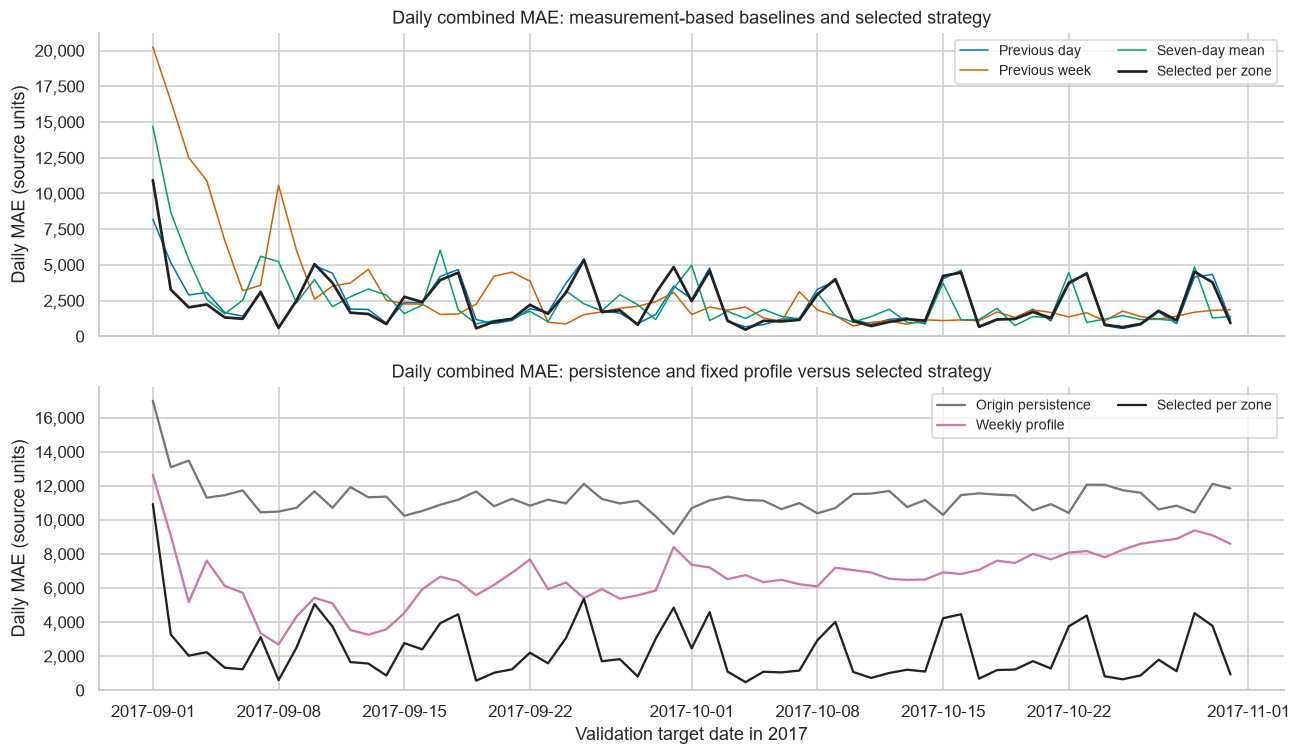

In [10]:
daily_errors={}
for baseline,frame in {**predictions,"selected_per_zone":selected}.items():
    daily_errors[baseline]=(frame-actual).abs().resample("D").mean()
daily_error_table=pd.concat(daily_errors,names=["baseline","target_date"])
save_table(daily_error_table,"08_daily_mae_all_baselines")
difficult_days=daily_errors["selected_per_zone"].nlargest(5,"total")
save_table(difficult_days,"09_largest_daily_combined_errors")
display(difficult_days.round(2))

fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for name in ["previous_day","previous_week","seven_day_mean","selected_per_zone"]:
    axes[0].plot(daily_errors[name].index,daily_errors[name]["total"],color=BASE_COLORS[name],
                 label=BASE_LABELS[name],linewidth=1.8 if name=="selected_per_zone" else 1)
axes[0].set_title("Daily combined MAE: measurement-based baselines and selected strategy")
for name in ["origin_persistence","weekly_profile","selected_per_zone"]:
    axes[1].plot(daily_errors[name].index,daily_errors[name]["total"],color=BASE_COLORS[name],label=BASE_LABELS[name])
axes[1].set_title("Daily combined MAE: persistence and fixed profile versus selected strategy")
for ax in axes:
    ax.set_ylabel("Daily MAE (source units)")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9,ncol=2)
    demand_axis(ax)
axes[1].set_xlabel("Validation target date in 2017")
show_figure(fig,"05_daily_combined_mae")

### Interpretation: Some Days Remain Difficult
The selected strategy's largest daily combined MAE occurs on **September 1**, at approximately **10,931.53 source units**. September 25 and September 10 are also among the largest-error days. September 1 is included under the daily-batch contract and was absent from the earlier rolling comparison.

These dates are candidates for later investigation, not evidence of an outage, a weather cause, or a data error. We do not remove them to improve the score.

The selected strategy's overall validation result averages across all 61 days. It should not be presented as the error expected on every individual day.

## 11. Error Patterns by Hour and Weekday
Summarise the selected strategy's mean absolute percentage errors by target hour and weekday. Percentage errors allow comparison across differently sized zones, while still weighting low-demand readings more strongly.

Both heatmaps use the same colour scale. Cells describe historical validation error categories, not forecast probabilities or confidence levels.

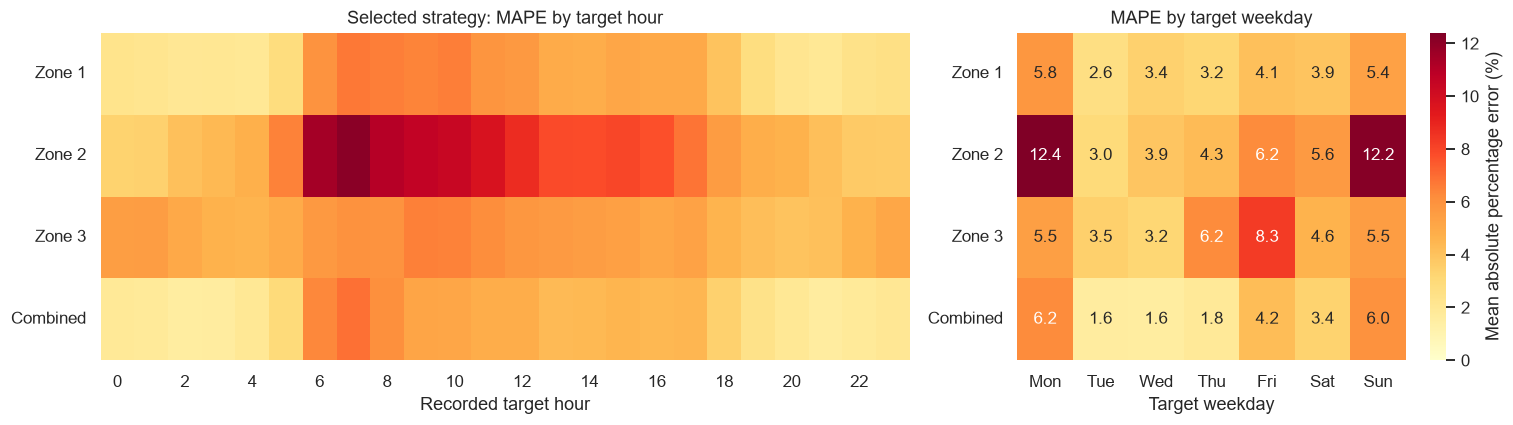

In [11]:
absolute_pct_error=selected_error.abs().div(actual)*100
hourly_mape=absolute_pct_error.groupby(absolute_pct_error.index.hour).mean().T.reindex(SERIES)
weekday_mape=absolute_pct_error.groupby(absolute_pct_error.index.day_of_week).mean().T.reindex(index=SERIES,columns=range(7))
save_table(hourly_mape,"10_selected_hourly_mape")
save_table(weekday_mape,"11_selected_weekday_mape")
vmax=max(hourly_mape.to_numpy().max(),weekday_mape.to_numpy().max())
fig,axes=plt.subplots(1,2,figsize=(14,4),gridspec_kw={"width_ratios":[2.5,1.5]})
sns.heatmap(hourly_mape,ax=axes[0],cmap="YlOrRd",vmin=0,vmax=vmax,cbar=False,
            xticklabels=2,yticklabels=[LABELS[s] for s in SERIES])
axes[0].set(title="Selected strategy: MAPE by target hour",xlabel="Recorded target hour",ylabel="")
sns.heatmap(weekday_mape,ax=axes[1],cmap="YlOrRd",vmin=0,vmax=vmax,annot=True,fmt=".1f",
            xticklabels=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"],yticklabels=[LABELS[s] for s in SERIES],
            cbar_kws={"label":"Mean absolute percentage error (%)"})
axes[1].set(title="MAPE by target weekday",xlabel="Target weekday",ylabel="")
for ax in axes:ax.tick_params(axis="y",rotation=0)
show_figure(fig,"06_selected_hour_weekday_error_patterns")

### Interpretation: Accuracy Varies by Time and Zone
The heatmaps locate time categories where the selected baseline has larger relative misses. Such patterns can motivate later calendar interactions or error analysis.

They do not justify repeatedly tuning models to validation subgroups without accounting for that selection. We will keep the same horizon and scoring rows and reserve the later final comparison for frozen choices.

A relatively low combined MAPE can coexist with higher zone-level errors because aggregation allows signed errors to cancel.

## 12. Errors by Forecast Lead Within the Daily Batch
Each day's forecast contains leads from 10 minutes to 24 hours. Group absolute percentage errors by the 144 lead slots, with 61 validation observations per slot.

The left panel compares combined-demand baselines, while the right shows the selected strategy by zone. This supplements the hourly heatmap with the exact lead associated with every target slot.

Because every batch is issued at the same clock time, **lead and target time of day are coupled**. These curves cannot isolate the effect of lead length from the daily demand pattern.

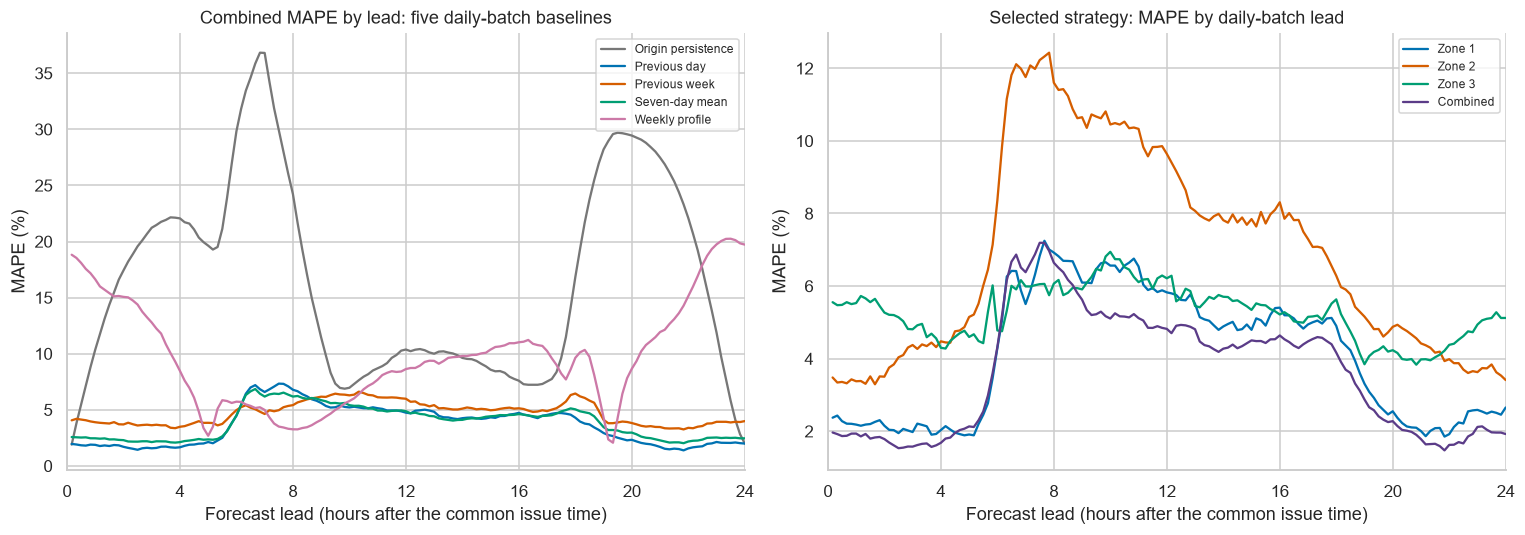

In [12]:
lead_tables={}
for baseline,frame in {**predictions,"selected_per_zone":selected}.items():
    ape=(frame-actual).abs().div(actual)*100
    table=ape.groupby(validation["lead_steps"].to_numpy()).mean()
    table.index.name="lead_steps"
    assert table.index.tolist()==list(range(1,145))
    lead_tables[baseline]=table
lead_error_table=pd.concat(lead_tables,names=["baseline","lead_steps"])
save_table(lead_error_table,"12_mape_by_batch_lead")
lead_counts=validation.groupby("lead_steps").size()
assert lead_counts.eq(61).all()
save_table(lead_counts.rename("validation_readings"),"13_batch_lead_counts")

fig,axes=plt.subplots(1,2,figsize=(14,5))
for baseline in BASELINES:
    table=lead_tables[baseline]
    axes[0].plot(table.index/6,table["total"],color=BASE_COLORS[baseline],label=BASE_LABELS[baseline])
axes[0].set_title("Combined MAPE by lead: five daily-batch baselines")
zone_colors={"zone1":"#0072B2","zone2":"#D55E00","zone3":"#009E73","total":"#5B3C88"}
for series in SERIES:
    table=lead_tables["selected_per_zone"]
    axes[1].plot(table.index/6,table[series],color=zone_colors[series],label=LABELS[series])
axes[1].set_title("Selected strategy: MAPE by daily-batch lead")
for ax in axes:
    ax.set(xlabel="Forecast lead (hours after the common issue time)",ylabel="MAPE (%)",xlim=(0,24),xticks=range(0,25,4))
    ax.legend(fontsize=8)
show_figure(fig,"09_daily_batch_lead_error_patterns")

### Interpretation: A Daily Batch Contains Different Lead Times
The forecast is frozen at the previous day's 23:50 issue, but its first target is only ten minutes ahead and its last target is 24 hours ahead.

The persistence curve demonstrates the limitations of repeating one value across a changing daily profile. The selected-strategy curves also show that its accuracy varies across the batch.

These are retrospective validation means, not forecast uncertainty bands. We do not claim that lead length alone caused any observed rise or fall in the errors.

## 13. Training-to-Validation Levels and Profile Failure
Compare actual demand means in training and validation with the fixed weekly profile's validation prediction mean. Also compare selected-strategy MAPE between September and October.

September contributes 30 scored days; October contributes 31. These diagnostics explain the validation results rather than redefining the score after seeing them.

,Training actual,Validation actual,Weekly profile prediction
zone1,33076.38,33107.51,33055.26
zone2,20539.36,20835.27,20511.97
zone3,20315.20,14079.85,20318.04


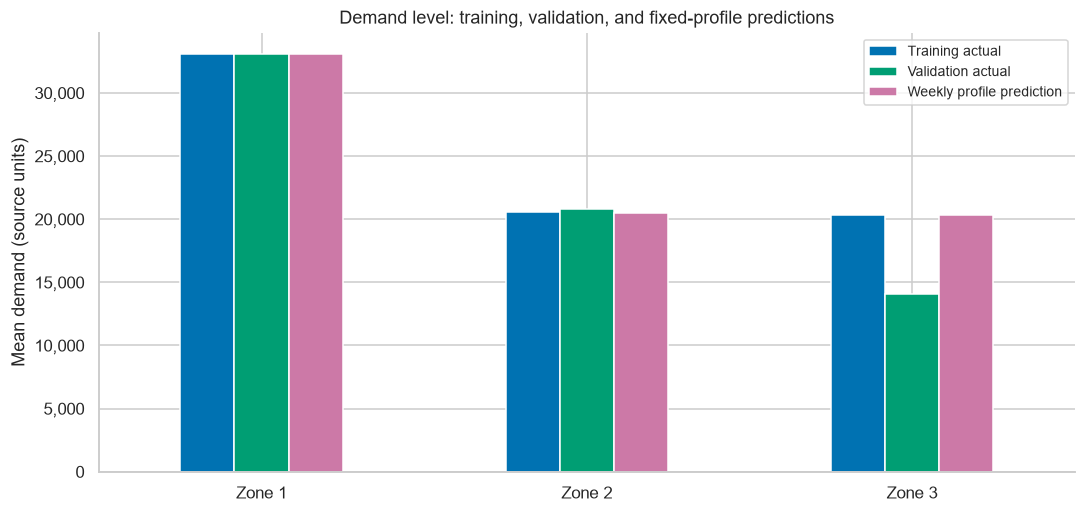

,month,series,n,MAE,RMSE,MAPE_pct,WAPE_pct,bias
0,9,zone1,4320,1499.215,2080.923,4.686,4.489,53.092
1,9,zone2,4320,1380.508,1940.118,7.127,6.841,-32.818
2,9,zone3,4320,947.660,1450.725,6.714,6.350,668.440
3,9,total,4320,2698.407,3945.384,4.147,3.939,688.715
4,10,zone1,4464,1115.905,1546.843,3.500,3.399,31.149
5,10,zone2,4464,1362.137,1966.882,6.661,6.345,-135.200
6,10,zone3,4464,482.563,613.500,3.873,3.638,158.502
7,10,total,4464,1979.536,2983.452,3.095,2.930,54.450


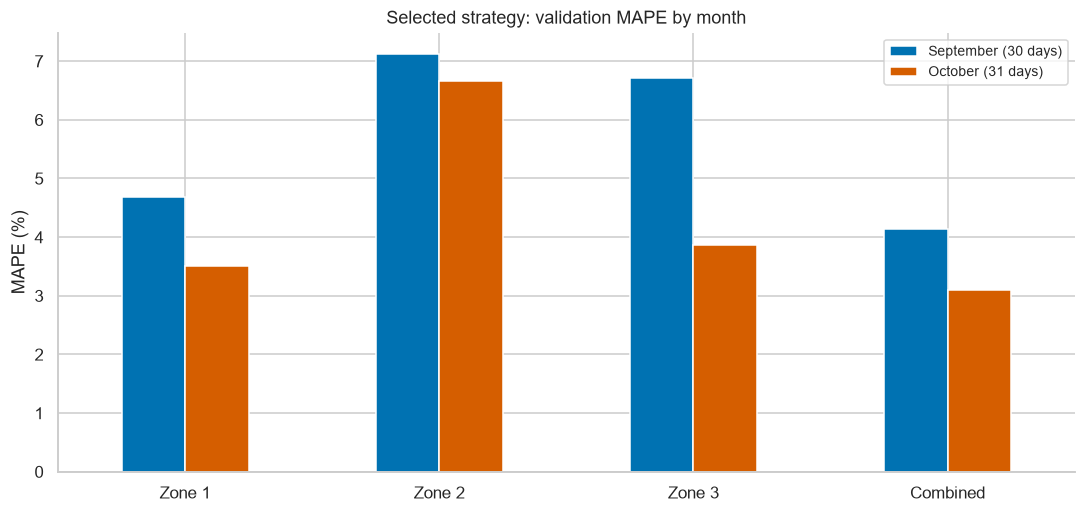

In [13]:
level_comparison=pd.DataFrame({"Training actual":train[[f"y_{z}" for z in ZONES]].mean().set_axis(ZONES),
    "Validation actual":actual[ZONES].mean(),"Weekly profile prediction":predictions["weekly_profile"][ZONES].mean()})
save_table(level_comparison,"14_training_validation_mean_levels")
display(level_comparison.round(2))
fig,ax=plt.subplots(figsize=(10,4.8))
level_comparison.rename(index=LABELS).plot.bar(ax=ax,rot=0,color=["#0072B2","#009E73","#CC79A7"])
ax.set(title="Demand level: training, validation, and fixed-profile predictions",xlabel="",ylabel="Mean demand (source units)")
ax.legend(fontsize=9)
demand_axis(ax)
show_figure(fig,"07_training_validation_level_comparison")

monthly_rows=[]
for month in [9,10]:
    mask=actual.index.month==month
    for series in SERIES:
        monthly_rows.append({"month":month,"series":series,
            **forecast_metrics(actual.loc[mask,series],selected.loc[mask,series])})
monthly_scores=pd.DataFrame(monthly_rows)
save_table(monthly_scores,"15_selected_monthly_validation_scores",index=False)
display(monthly_scores.round(3))
fig,ax=plt.subplots(figsize=(10,4.8))
month_plot=monthly_scores.pivot(index="series",columns="month",values="MAPE_pct").reindex(SERIES)
month_plot.rename(index=LABELS,columns={9:"September (30 days)",10:"October (31 days)"}).plot.bar(ax=ax,rot=0,color=["#0072B2","#D55E00"])
ax.set(title="Selected strategy: validation MAPE by month",xlabel="",ylabel="MAPE (%)")
ax.legend(fontsize=9)
show_figure(fig,"08_selected_monthly_mape")

### Interpretation: A Fixed Historical Profile Can Miss a Level Change
The weekly profile carries training-period average levels into validation. Zone 3's observed September–October level is much lower than the profile predicts, explaining its persistent overprediction.

More recent demand-based rules adapt as new readings become available, although they still make substantial errors on some days. This motivates comparing advanced models with strong recent-history baselines rather than only with a weak fixed average.

Month-specific scores also show that one overall number can hide differences within the evaluation period. They do not establish how November–December will perform.

## 14. Save Predictions, Baseline Rules, and Evidence
Save validation predictions only, including actuals and errors for each baseline and for the selected strategy. The saved JSON records which baseline is selected for each zone and how that choice was made.

These outputs are reproducible from the notebooks. No advanced model has been fitted, and no test scores or peak thresholds are produced here.

In [14]:
prediction_parts=[]
origins=validation.set_index("target_time")["origin_time"]
for baseline,frame in {**predictions,"selected_per_zone":selected}.items():
    for series in SERIES:
        part=pd.DataFrame({"target_time":actual.index,"origin_time":origins.to_numpy(),
            "lead_steps":validation["lead_steps"].to_numpy(),
            "baseline":baseline,"series":series,"actual":actual[series].to_numpy(),
            "prediction":frame[series].to_numpy()})
        part["error"]=part["prediction"]-part["actual"]
        part["absolute_error"]=part["error"].abs()
        part["absolute_percentage_error"]=part["absolute_error"]/part["actual"]*100
        prediction_parts.append(part)
prediction_long=pd.concat(prediction_parts,ignore_index=True)
assert len(prediction_long)==8784*4*6
assert prediction_long["target_time"].max()<pd.Timestamp(manifest["validation_cutoff_exclusive"])
prediction_path=PROCESSED_DIR/"baseline_validation_daily_batch.parquet"
prediction_long.to_parquet(prediction_path,index=False,engine="pyarrow")
pd.testing.assert_frame_equal(prediction_long,pd.read_parquet(prediction_path))
selection_contract={
    "design_id":"daily_batch_2350","step_minutes":10,"forecast_design":manifest["forecast_design"],
    "issue_clock":"23:50 previous day","targets_per_issue":144,"lead_steps_min":1,"lead_steps_max":144,
    "selection_period":"validation only: 2017-09-01 through 2017-10-31",
    "selection_metric":"MAE per zone; exact ties follow declared baseline order",
    "selected_baseline_by_zone":champions,"baseline_order":BASELINES,
    "combined_rule":"Sum selected zone predictions at matching target timestamps",
    "profile_fit_latest_label":str(latest_fit_label),
    "feature_manifest_file":manifest_path.name,
    "feature_manifest_sha256":hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "source_feature_sha256":manifest["feature_sha256"],
    "test_scored":False,"full_file_previously_explored":True,
    "validation_scores":json.loads(selected_scores.to_json(orient="records")),
}
selection_path=BASE_MODELS/"baseline_selection_daily_batch.json"
selection_path.write_text(json.dumps(selection_contract,indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")
figure_names=["01_validation_mae_comparison","02_first_validation_week_forecasts",
    "03_selected_actual_prediction_density","04_selected_signed_error_distributions",
    "05_daily_combined_mae","06_selected_hour_weekday_error_patterns",
    "07_training_validation_level_comparison","08_selected_monthly_mape",
    "09_daily_batch_lead_error_patterns"]
for name in figure_names:
    for extension in ["png","svg"]:assert (BASE_FIGURES/f"{name}.{extension}").stat().st_size>0
assert hashlib.sha256(clean_path.read_bytes()).hexdigest()==manifest["source_sha256"]
assert hashlib.sha256(feature_path.read_bytes()).hexdigest()==manifest["feature_sha256"]
print("Validation predictions saved:",prediction_path)
print("Selected rules saved:",selection_path)
print("Five baseline methods compared; selected strategy recorded separately.")
print("Nine figures verified. Cleaned source and feature inputs unchanged. No test scores calculated.")

Validation predictions saved: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\processed\baseline_validation_daily_batch.parquet
Selected rules saved: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\models\05_baselines_daily_batch\baseline_selection_daily_batch.json
Five baseline methods compared; selected strategy recorded separately.
Nine figures verified. Cleaned source and feature inputs unchanged. No test scores calculated.


## 15. Conclusions and Next Step
We compared five simple baselines on identical next-day daily-batch validation targets. Every day's 144 forecasts share the previous day's 23:50 issue time. Previous day is the MAE benchmark for Zones 1 and 2; the seven-day same-clock mean narrowly wins MAE for Zone 3.

The selected coherent combined forecast has validation MAE approximately **2,333.08 source units** and MAPE approximately **3.61%**. These are validation-selection results and must not be presented as independent final test performance.

### Explain during the defence
- A forecast's origin and horizon determine which observations are eligible.
- Previous day preserves the preceding daily profile; origin persistence repeats one late-evening value across the whole batch.
- Leads range from 10 minutes to 24 hours, and a fixed daily issue couples lead with target clock time.
- The weekly profile uses training labels only and can still fail under a level change.
- MAE and RMSE can favour different methods; our declared criterion is MAE.
- Combined error can be smaller because zone errors offset, so zone-level evaluation remains essential.
- Historical errors are not forecast intervals, and difficult days were retained.
- The final test window has not been scored here, despite earlier descriptive exposure.

### Next: Notebook 06 — Forecasting Models
Fit and compare model candidates using training-only preprocessing and chronological validation. Use the same target timestamps and information boundary as these baselines. Compare calendar/past-demand models with and without eligible historical weather information.

After choices are frozen, plan the final fit and test comparison consistently. Peak-alert definitions and thresholds will be handled explicitly in the later peak-monitoring notebook rather than inferred from full-file high percentiles.